# INFO3020 · Giữa kỳ — Báo cáo EDA: Nghỉ việc của nhân viên (IBM HR Attrition)

**Sinh viên:** Phan Hoàng Bách
**Câu hỏi nghiên cứu:** *Nhóm nhân viên nào có tỷ lệ nghỉ việc cao nhất, và yếu tố nào vẫn gắn với nghỉ việc sau khi đã so sánh trong cùng cấp bậc công việc?*

Notebook này chạy trọn vẹn bằng **Restart & Run All**. Mọi bảng và biểu đồ hiển thị **ngay trong notebook**, không ghi ra file nào khác. Đầu vào duy nhất là file `EmployeeAttrition.csv`, **đặt cùng thư mục với notebook**.

Cấu trúc: (1) Nạp dữ liệu → (2) Đánh giá chất lượng → (3) Làm sạch + nhật ký, 3.1 Ngoại lai → (4) Từ điển dữ liệu → (5) Thống kê mô tả 4 nhóm → (6) Phân tích theo nhóm & biến gây nhiễu → (7) Kiểm tra độ vững → (8) Năm biểu đồ chính.

In [ ]:
from pathlib import Path
from IPython.display import display

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

def df_map(d, f):
    """Áp hàm cho từng ô — chạy được cả pandas cũ (applymap) lẫn mới (map)."""
    return d.map(f) if hasattr(d, "map") else d.applymap(f)

RAW = Path("EmployeeAttrition.csv")

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

ACCENT = "#eb6834"
NEUTRAL = "#b9b8b2" 
BLUE = "#2a78d6" 
INK, INK2 = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": INK2, "axes.labelcolor": INK, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "figure.dpi": 110,
})
SOURCE_NOTE = "Nguồn: IBM HR Analytics Employee Attrition (dữ liệu giả lập do IBM tạo), n = 1.470 nhân viên, chụp tại một thời điểm."

## 1. Nạp dữ liệu gốc

Dòng tiêu đề của file có ký tự BOM (`\ufeff`) — nếu đọc bằng `utf-8` thường, cột đầu tiên sẽ có tên `\ufeffAge`. Dùng `encoding="utf-8-sig"` để loại bỏ.

In [2]:
with open(RAW, "rb") as f:
    head_bytes = f.read(3)
print("3 byte đầu của file:", head_bytes, "→ có BOM" if head_bytes == b"\xef\xbb\xbf" else "→ không có BOM")

raw = pd.read_csv(RAW, encoding="utf-8-sig")
print("Kích thước:", raw.shape)
raw.head()

3 byte đầu của file: b'\xef\xbb\xbf' → có BOM
Kích thước: (1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14  JobLevel                  1470 non-null   int64
 15

## 2. Đánh giá chất lượng dữ liệu (6 chiều — Tuần 3)

Kiểm tra từng chiều bằng code, kết quả dùng làm bằng chứng cho điểm 1–5 trong báo cáo.

In [ ]:
df = raw.copy()
audit = {}

n_nan = int(df.isna().sum().sum())
disguised_tokens = {"", "na", "n/a", "nan", "null", "none", "-", "?", "unknown"}
obj_cols = df.select_dtypes(include=["object", "string"]).columns
n_disguised = int(sum(df[c].astype(str).str.strip().str.lower().isin(disguised_tokens).sum() for c in obj_cols))
n_negative = int((df.select_dtypes("number") < 0).sum().sum())
audit["Completeness"] = f"{n_nan} ô NaN; {n_disguised} giá trị thiếu trá hình dạng chữ; {n_negative} giá trị âm kiểu -999"

n_dup = int(df.duplicated().sum())
n_dup_noid = int(df.drop(columns="EmployeeNumber").duplicated().sum())
audit["Uniqueness"] = f"{n_dup} dòng trùng hoàn toàn; {n_dup_noid} dòng trùng khi bỏ mã NV; EmployeeNumber duy nhất = {df.EmployeeNumber.is_unique}"

domains = {"Education": range(1, 6), "EnvironmentSatisfaction": range(1, 5), "JobInvolvement": range(1, 5),
           "JobSatisfaction": range(1, 5), "RelationshipSatisfaction": range(1, 5), "WorkLifeBalance": range(1, 5),
           "PerformanceRating": range(1, 5), "JobLevel": range(1, 6), "StockOptionLevel": range(0, 4)}
bad_domain = {c: int((~df[c].isin(list(r))).sum()) for c, r in domains.items()}
audit["Validity"] = f"Số giá trị ngoài miền: {sum(bad_domain.values())} (kiểm {len(domains)} cột thang đo)"

checks = {
    "YearsAtCompany > TotalWorkingYears": (df.YearsAtCompany > df.TotalWorkingYears).sum(),
    "YearsInCurrentRole > YearsAtCompany": (df.YearsInCurrentRole > df.YearsAtCompany).sum(),
    "YearsWithCurrManager > YearsAtCompany": (df.YearsWithCurrManager > df.YearsAtCompany).sum(),
    "YearsSinceLastPromotion > YearsAtCompany": (df.YearsSinceLastPromotion > df.YearsAtCompany).sum(),
    "Age - TotalWorkingYears < 18": ((df.Age - df.TotalWorkingYears) < 18).sum(),
    "NumCompaniesWorked == 0 nhưng TotalWorkingYears > YearsAtCompany":
        ((df.NumCompaniesWorked == 0) & (df.TotalWorkingYears > df.YearsAtCompany)).sum(),
}
checks = {k: int(v) for k, v in checks.items()}
audit["Consistency"] = "; ".join(f"{k}: {v}" for k, v in checks.items())

rate_corr = df[["DailyRate", "HourlyRate", "MonthlyRate", "MonthlyIncome", "JobLevel"]].corr("spearman").round(2)
audit["Accuracy"] = (f"Spearman(DailyRate, MonthlyIncome) = {rate_corr.loc['DailyRate','MonthlyIncome']}, "
                     f"(HourlyRate, MonthlyIncome) = {rate_corr.loc['HourlyRate','MonthlyIncome']}, "
                     f"(MonthlyRate, MonthlyIncome) = {rate_corr.loc['MonthlyRate','MonthlyIncome']}")
audit["Timeliness"] = "Không có cột ngày tháng; nguồn không công bố thời điểm thu thập"

for k, v in audit.items():
    print(f"{k:13s} | {v}")
print("\nGiá trị ngoài miền theo cột:", bad_domain)

Completeness  | 0 ô NaN; 0 giá trị thiếu trá hình dạng chữ; 0 giá trị âm kiểu -999
Uniqueness    | 0 dòng trùng hoàn toàn; 0 dòng trùng khi bỏ mã NV; EmployeeNumber duy nhất = True
Validity      | Số giá trị ngoài miền: 0 (kiểm 9 cột thang đo)
Consistency   | YearsAtCompany > TotalWorkingYears: 0; YearsInCurrentRole > YearsAtCompany: 0; YearsWithCurrManager > YearsAtCompany: 0; YearsSinceLastPromotion > YearsAtCompany: 0; Age - TotalWorkingYears < 18: 0; NumCompaniesWorked == 0 nhưng TotalWorkingYears > YearsAtCompany: 197
Accuracy      | Spearman(DailyRate, MonthlyIncome) = 0.02, (HourlyRate, MonthlyIncome) = -0.02, (MonthlyRate, MonthlyIncome) = 0.05
Timeliness    | Không có cột ngày tháng; nguồn không công bố thời điểm thu thập

Giá trị ngoài miền theo cột: {'Education': 0, 'EnvironmentSatisfaction': 0, 'JobInvolvement': 0, 'JobSatisfaction': 0, 'RelationshipSatisfaction': 0, 'WorkLifeBalance': 0, 'PerformanceRating': 0, 'JobLevel': 0, 'StockOptionLevel': 0}


In [ ]:
nunique = df.nunique()
const_cols = nunique[nunique == 1].index.tolist()
print("Cột chỉ có 1 giá trị:", {c: df[c].iloc[0] for c in const_cols})
print("PerformanceRating:", df.PerformanceRating.value_counts().to_dict())
print(df[["DailyRate", "HourlyRate", "MonthlyRate"]].agg(["min", "max", "skew", "kurt"]).round(2))
rate_corr

Cột chỉ có 1 giá trị: {'EmployeeCount': np.int64(1), 'Over18': 'Y', 'StandardHours': np.int64(80)}
PerformanceRating: {3: 1244, 4: 226}
      DailyRate  HourlyRate  MonthlyRate
min       102.0       30.00      2094.00
max      1499.0      100.00     26999.00
skew       -0.0       -0.03         0.02
kurt       -1.2       -1.20        -1.21


,DailyRate,HourlyRate,MonthlyRate,MonthlyIncome,JobLevel
DailyRate,1.00,0.02,-0.03,0.02,0.00
HourlyRate,0.02,1.00,-0.01,-0.02,-0.03
MonthlyRate,-0.03,-0.01,1.00,0.05,0.05
MonthlyIncome,0.02,-0.02,0.05,1.00,0.92
JobLevel,0.00,-0.03,0.05,0.92,1.00


## 3. Làm sạch dữ liệu — mỗi bước ghi một dòng vào nhật ký

Mẫu nhật ký theo Tuần 4: **Bước | Cột | Phát hiện | Hành động | Số dòng | Lý do (và cách xác minh)**. Quyết định *không* can thiệp cũng được ghi.

In [ ]:
log = []
def log_step(step, col, finding, action, rows, why):
    log.append({"Bước": step, "Cột": col, "Phát hiện": finding, "Hành động": action, "Số dòng": rows, "Lý do / cách xác minh": why})

clean = raw.copy()
N = len(clean)

log_step("1", "Age (tiêu đề)", "Tiêu đề cột đầu có ký tự BOM \\ufeff",
         "Đọc lại bằng encoding='utf-8-sig'", N, "Kiểm 3 byte đầu file = EF BB BF; không xử lý thì df['Age'] báo KeyError")

log_step("2", "Tất cả", f"{n_nan} ô NaN; {n_disguised} giá trị thiếu trá hình; {n_negative} mã âm kiểu -999",
         "Không cần điền/xoá", 0,
         "Quét isna(), các chuỗi 'N/A','-','?','unknown'…, và giá trị âm; số 0 ở YearsAtCompany/TrainingTimes là hợp lệ (nhân viên mới)")

log_step("3", "Tất cả", f"{n_dup} dòng trùng; {n_dup_noid} dòng trùng khi bỏ mã NV; mã NV duy nhất",
         "Không xoá", 0, "duplicated() trên toàn bộ cột và trên các cột trừ EmployeeNumber")

clean = clean.drop(columns=const_cols)
log_step("4", ", ".join(const_cols), "Mỗi cột chỉ có 1 giá trị (1 / 'Y' / 80)",
         f"Loại bỏ {len(const_cols)} cột", N, "Phương sai = 0, không thể phân biệt nhân viên; StandardHours=80 cho mọi người nên không đo được giờ làm thực tế")

clean = clean.set_index("EmployeeNumber")
log_step("5", "EmployeeNumber", f"Mã duy nhất nhưng đứt quãng (1–{raw.EmployeeNumber.max()} cho {N} người)",
         "Chuyển thành chỉ mục, không dùng làm biến phân tích", N,
         "Là định danh, không phải đặc điểm; khoảng trống gợi ý đây là mẫu con của một tập lớn hơn (ghi vào phần giới hạn)")

clean["Left"] = (clean["Attrition"] == "Yes").astype(int)
log_step("6", "Attrition", "Giá trị 'Yes'/'No' (237/1.233)",
         "Thêm cột Left = 1/0, giữ cột gốc", N, "Tính tỷ lệ nghỉ việc bằng trung bình của Left; kiểm chỉ có đúng 2 giá trị")

LABELS = {
    "Education": {1: "Dưới CĐ", 2: "Cao đẳng", 3: "Cử nhân", 4: "Thạc sĩ", 5: "Tiến sĩ"},
    "EnvironmentSatisfaction": {1: "Thấp", 2: "Trung bình", 3: "Cao", 4: "Rất cao"},
    "JobSatisfaction": {1: "Thấp", 2: "Trung bình", 3: "Cao", 4: "Rất cao"},
    "RelationshipSatisfaction": {1: "Thấp", 2: "Trung bình", 3: "Cao", 4: "Rất cao"},
    "JobInvolvement": {1: "Thấp", 2: "Trung bình", 3: "Cao", 4: "Rất cao"},
    "WorkLifeBalance": {1: "Kém", 2: "Tốt", 3: "Khá tốt", 4: "Rất tốt"},
    "PerformanceRating": {1: "Thấp", 2: "Đạt", 3: "Xuất sắc", 4: "Vượt trội"},
}
for c, m in LABELS.items():
    clean[c + "_label"] = pd.Categorical(clean[c].map(m), categories=list(m.values()), ordered=True)
log_step("7", "Education, 4 cột Satisfaction/Involvement, WorkLifeBalance, PerformanceRating",
         "Mã số 1–5/1–4 không kèm nhãn trong file",
         "Thêm cột *_label dạng phân loại có thứ tự; giữ mã số", N,
         "Bảng mã theo mô tả gốc của bộ dữ liệu (OpenML/Kaggle); thang thứ bậc nên báo cáo trung vị/tỷ lệ, không dùng trung bình như số đo khoảng")

n_logic = sum(v for k, v in checks.items() if not k.startswith("NumCompanies"))
log_step("8", "6 cột số năm (Years…, TotalWorkingYears) và Age",
         f"{n_logic} dòng vi phạm 5 ràng buộc logic", "Không cần sửa", 0,
         "Kiểm: năm tại công ty ≤ tổng năm làm việc; năm ở vị trí/với quản lý/từ lần thăng chức ≤ năm tại công ty; tuổi − tổng năm làm việc ≥ 18")

m0 = clean.NumCompaniesWorked == 0
gap = (clean.TotalWorkingYears - clean.YearsAtCompany)[m0]
clean["NCW_flag"] = m0.astype(int)
log_step("9", "NumCompaniesWorked", f"{int(m0.sum())} người ghi 0 công ty trước đây nhưng tổng năm làm việc lớn hơn năm tại công ty đúng {int(gap.min())} năm ({int((gap == gap.min()).sum())}/{int(m0.sum())} dòng)",
         "Giữ nguyên, thêm cờ NCW_flag; không dùng cột này để kết luận", int(m0.sum()),
         "Mẫu lệch đều đúng 1 năm gợi ý lỗi mã hoá hệ thống, nhưng không có nguồn để xác minh giá trị đúng → đánh dấu thay vì đoán")

log_step("10", "DailyRate, HourlyRate, MonthlyRate",
         "Phân phối đều (kurtosis ≈ −1,2), tương quan với MonthlyIncome ≈ 0 (|ρ| ≤ 0,05), không tăng theo JobLevel",
         "Giữ trong bảng dữ liệu sạch, loại khỏi phân tích", 0,
         "Không có định nghĩa trong nguồn và mâu thuẫn với thu nhập thực nhận → không đủ căn cứ để diễn giải")

NUM_OUT = ["Age", "MonthlyIncome", "TotalWorkingYears", "YearsAtCompany", "YearsInCurrentRole",
           "YearsSinceLastPromotion", "YearsWithCurrManager", "DistanceFromHome", "NumCompaniesWorked",
           "PercentSalaryHike", "TrainingTimesLastYear"]
q1, q3 = clean.MonthlyIncome.quantile([.25, .75]); fence = q3 + 1.5 * (q3 - q1)
out_inc = clean.MonthlyIncome > fence
z_inc = ((clean.MonthlyIncome - clean.MonthlyIncome.mean()) / clean.MonthlyIncome.std()).abs() > 3
lv = ", ".join(f"cấp {k}: {v}" for k, v in clean.loc[out_inc, "JobLevel"].value_counts().sort_index().items())
med_i = clean.MonthlyIncome.median(); mz_inc = (0.6745 * (clean.MonthlyIncome - med_i) / (clean.MonthlyIncome - med_i).abs().median()).abs() > 3.5
log_step("11", "MonthlyIncome", f"IQR đánh dấu {int(out_inc.sum())} dòng > {fence:,.0f}".replace(",", ".") + f"; Z cải tiến (MAD) đánh dấu {int(mz_inc.sum())}; Z-score (>3) đánh dấu {int(z_inc.sum())}",
         "Giữ toàn bộ; dùng trung vị, Spearman và so sánh trong cùng cấp", int(out_inc.sum()),
         f"Tất cả thuộc cấp bậc 4–5 ({lv}) — lương cao thật của cấp quản lý; trong từng cấp không ai vượt khung lương; bỏ các dòng này không đổi kết luận (mục 3.1)")

flag_other = {c: int((~clean[c].between(*(lambda a, b: (a - 1.5 * (b - a), b + 1.5 * (b - a)))(*clean[c].quantile([.25, .75]))) ).sum())
              for c in NUM_OUT if c != "MonthlyIncome"}
n_other = int(pd.concat([~clean[c].between(*(lambda a, b: (a - 1.5 * (b - a), b + 1.5 * (b - a)))(*clean[c].quantile([.25, .75])))
                         for c in NUM_OUT if c != "MonthlyIncome"], axis=1).any(axis=1).sum())
log_step("12", "10 cột số còn lại (Age, các cột số năm, NumCompaniesWorked, TrainingTimesLastYear…)",
         "IQR đánh dấu: " + ", ".join(f"{c} {v}" for c, v in flag_other.items() if v) + "; Age, DistanceFromHome, PercentSalaryHike: 0",
         "Giữ toàn bộ", n_other,
         "Không có giá trị không thể có (kiểm miền và logic B8); cột số năm là nhân viên gắn bó lâu; TrainingTimesLastYear bị đánh dấu chỉ vì Q1–Q3 quá hẹp (mục 3.1)")

clean["AgeBand"] = pd.cut(clean.Age, [17, 29, 39, 60], labels=["18–29", "30–39", "40–60"])
clean["TenureBand"] = pd.cut(clean.YearsAtCompany, [-1, 1, 3, 5, 10, 40], labels=["0–1", "2–3", "4–5", "6–10", "11+"])
clean["IncomeQuartile"] = pd.qcut(clean.MonthlyIncome, 4, labels=["Q1 (thấp)", "Q2", "Q3", "Q4 (cao)"])
log_step("13", "AgeBand, TenureBand, IncomeQuartile", "Cần nhóm hoá để so sánh tỷ lệ nghỉ việc",
         "Tuổi: 18–29/30–39/40–60; thâm niên: 0–1/2–3/4–5/6–10/11+ năm; thu nhập: tứ phân vị", N,
         "Ngưỡng cố định trước khi xem kết quả; mỗi nhóm ≥ 200 người để tỷ lệ không dao động vì cỡ mẫu nhỏ")

cleaning_log = pd.DataFrame(log)
print("Kích thước sau làm sạch:", clean.shape)
cleaning_log

Kích thước sau làm sạch: (1470, 43)


,Bước,Cột,Phát hiện,Hành động,Số dòng,Lý do / cách xác minh
0,1,Age (tiêu đề),Tiêu đề cột đầu có ký tự BOM \ufeff,Đọc lại bằng encoding='utf-8-sig',1470,Kiểm 3 byte đầu file = EF BB BF; không xử lý t...
1,2,Tất cả,0 ô NaN; 0 giá trị thiếu trá hình; 0 mã âm kiể...,Không cần điền/xoá,0,"Quét isna(), các chuỗi 'N/A','-','?','unknown'..."
2,3,Tất cả,0 dòng trùng; 0 dòng trùng khi bỏ mã NV; mã NV...,Không xoá,0,duplicated() trên toàn bộ cột và trên các cột ...
3,4,"EmployeeCount, Over18, StandardHours",Mỗi cột chỉ có 1 giá trị (1 / 'Y' / 80),Loại bỏ 3 cột,1470,"Phương sai = 0, không thể phân biệt nhân viên;..."
4,5,EmployeeNumber,Mã duy nhất nhưng đứt quãng (1–2068 cho 1470 n...,"Chuyển thành chỉ mục, không dùng làm biến phân...",1470,"Là định danh, không phải đặc điểm; khoảng trốn..."
5,6,Attrition,Giá trị 'Yes'/'No' (237/1.233),"Thêm cột Left = 1/0, giữ cột gốc",1470,Tính tỷ lệ nghỉ việc bằng trung bình của Left;...
6,7,"Education, 4 cột Satisfaction/Involvement, Wor...",Mã số 1–5/1–4 không kèm nhãn trong file,Thêm cột *_label dạng phân loại có thứ tự; giữ...,1470,Bảng mã theo mô tả gốc của bộ dữ liệu (OpenML/...
7,8,"6 cột số năm (Years…, TotalWorkingYears) và Age",0 dòng vi phạm 5 ràng buộc logic,Không cần sửa,0,Kiểm: năm tại công ty ≤ tổng năm làm việc; năm...
8,9,NumCompaniesWorked,197 người ghi 0 công ty trước đây nhưng tổng n...,"Giữ nguyên, thêm cờ NCW_flag; không dùng cột n...",197,Mẫu lệch đều đúng 1 năm gợi ý lỗi mã hoá hệ th...
9,10,"DailyRate, HourlyRate, MonthlyRate","Phân phối đều (kurtosis ≈ −1,2), tương quan vớ...","Giữ trong bảng dữ liệu sạch, loại khỏi phân tích",0,Không có định nghĩa trong nguồn và mâu thuẫn v...


### 3.1 Ngoại lai (outlier): nhìn → phát hiện → điều tra → quyết định → kiểm tra ảnh hưởng

Làm theo trình tự của Tuần 4: (1) **nhìn trước khi tính** (boxplot); (2) **phát hiện** bằng ba phương pháp — Z-score, Z-score cải tiến (MAD) và IQR — vì mỗi phương pháp hỏng ở chỗ khác nhau; (3) **điều tra** từng nhóm bị đánh dấu: giá trị đó *không thể có*, *khó tin* hay chỉ *hiếm gặp*; (4) **quyết định** giữ / xoá / chặn trần / biến đổi, có lý do; (5) **kiểm tra** kết luận chính có đổi không nếu bỏ các dòng ngoại lai.

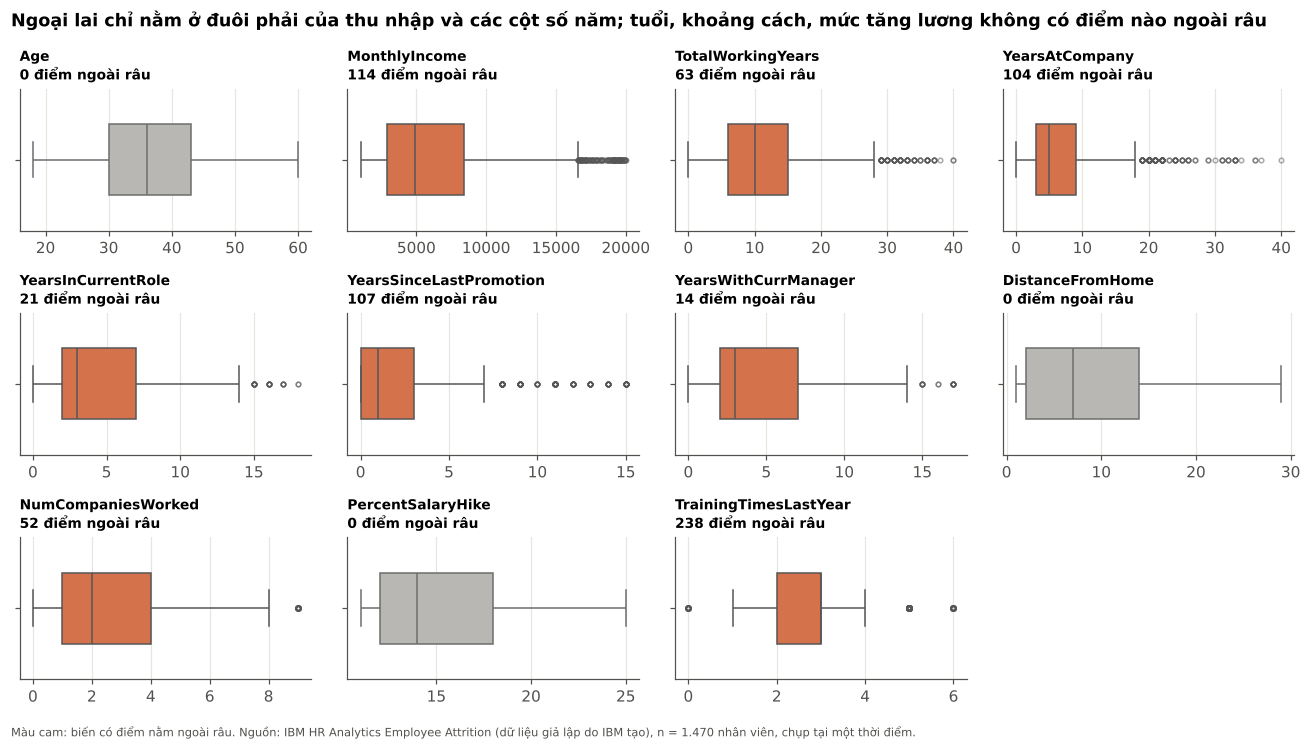

In [ ]:
fig, axes = plt.subplots(3, 4, figsize=(12, 6.6))
for ax, col in zip(axes.flat, NUM_OUT):
    q1, q3 = clean[col].quantile([.25, .75])
    k = int((~clean[col].between(q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1))).sum())
    sns.boxplot(x=clean[col], ax=ax, color=ACCENT if k > 0 else NEUTRAL, width=.5,
                flierprops={"marker": "o", "markersize": 3, "alpha": .5})
    ax.set_title(f"{col}\n{k} điểm ngoài râu", fontsize=9); ax.set_xlabel("")
axes.flat[-1].axis("off")
fig.suptitle("Ngoại lai chỉ nằm ở đuôi phải của thu nhập và các cột số năm; tuổi, khoảng cách, mức tăng lương không có điểm nào ngoài râu",
             x=0.01, ha="left", fontweight="bold", fontsize=11.5)
fig.tight_layout()
fig.text(0.01, -0.02, "Màu cam: biến có điểm nằm ngoài râu. " + SOURCE_NOTE, fontsize=7.5, color=INK2)
plt.show()

In [ ]:
def detect(x):
    z = (x - x.mean()) / x.std()                                   # Z-score: |z| > 3
    med = x.median(); mad = (x - med).abs().median()
    m = 0.6745 * (x - med) / mad if mad > 0 else z * np.nan        # Z-score cải tiến: |M| > 3,5
    q1, q3 = x.quantile([.25, .75]); iqr = q3 - q1
    return {"Nhỏ nhất": x.min(), "Trung vị": med, "Lớn nhất": x.max(), "Skewness": round(x.skew(), 2),
            "Z-score |z|>3": int((z.abs() > 3).sum()),
            "Z cải tiến |M|>3,5": int((m.abs() > 3.5).sum()),
            "IQR × 1,5": int((~x.between(q1 - 1.5 * iqr, q3 + 1.5 * iqr)).sum()),
            "IQR × 3": int((~x.between(q1 - 3 * iqr, q3 + 3 * iqr)).sum()),
            "Ngưỡng trên IQR": q3 + 1.5 * iqr}

out_tbl = pd.DataFrame({c: detect(clean[c]) for c in NUM_OUT}).T
iqr_flag = pd.DataFrame({c: ~clean[c].between(*(lambda q1, q3: (q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)))(*clean[c].quantile([.25, .75])))
                         for c in NUM_OUT})
out_tbl["Tỷ lệ nghỉ trong nhóm bị IQR đánh dấu"] = [clean.Left[iqr_flag[c]].mean() if iqr_flag[c].any() else np.nan for c in NUM_OUT]
display(out_tbl.round(3))
print(f"Tỷ lệ nghỉ chung: {clean.Left.mean():.3f}")
print("Ba phương pháp cho ba con số khác nhau — ví dụ MonthlyIncome: Z-score đánh dấu", int(out_tbl.loc["MonthlyIncome", "Z-score |z|>3"]),
      "vì phân phối lệch phải làm độ lệch chuẩn phình to (hiệu ứng che lấp — masking); Z cải tiến và IQR đều đánh dấu hơn 110 dòng.")

,Nhỏ nhất,Trung vị,Lớn nhất,Skewness,Z-score |z|>3,"Z cải tiến |M|>3,5","IQR × 1,5",IQR × 3,Ngưỡng trên IQR,Tỷ lệ nghỉ trong nhóm bị IQR đánh dấu
Age,18.0,36.0,60.0,0.41,0.0,0.0,0.0,0.0,62.5,NaN
MonthlyIncome,1009.0,4919.0,19999.0,1.37,0.0,118.0,114.0,0.0,16581.0,0.044
TotalWorkingYears,0.0,10.0,40.0,1.12,16.0,46.0,63.0,0.0,28.5,0.079
YearsAtCompany,0.0,5.0,40.0,1.76,25.0,66.0,104.0,19.0,18.0,0.096
YearsInCurrentRole,0.0,3.0,18.0,0.92,13.0,0.0,21.0,0.0,14.5,0.095
YearsSinceLastPromotion,0.0,1.0,15.0,1.98,42.0,183.0,107.0,32.0,7.5,0.121
YearsWithCurrManager,0.0,3.0,17.0,0.83,14.0,0.0,14.0,0.0,14.5,0.000
DistanceFromHome,1.0,7.0,29.0,0.96,0.0,0.0,0.0,0.0,32.0,NaN
NumCompaniesWorked,0.0,2.0,9.0,1.03,0.0,101.0,52.0,0.0,8.5,0.231
PercentSalaryHike,11.0,14.0,25.0,0.82,0.0,18.0,0.0,0.0,27.0,NaN


Tỷ lệ nghỉ chung: 0.161
Ba phương pháp cho ba con số khác nhau — ví dụ MonthlyIncome: Z-score đánh dấu 0 vì phân phối lệch phải làm độ lệch chuẩn phình to (hiệu ứng che lấp — masking); Z cải tiến và IQR đều đánh dấu hơn 110 dòng.


In [ ]:
impossible = {
    "Age ngoài 18–65": (~clean.Age.between(18, 65)).sum(),
    "MonthlyIncome ≤ 0": (clean.MonthlyIncome <= 0).sum(),
    "Cột số năm < 0": (clean[["TotalWorkingYears", "YearsAtCompany", "YearsInCurrentRole",
                              "YearsSinceLastPromotion", "YearsWithCurrManager"]] < 0).sum().sum(),
    "Tổng năm làm việc > Tuổi − 14": (clean.TotalWorkingYears > clean.Age - 14).sum(),
    "PercentSalaryHike ngoài 0–100": (~clean.PercentSalaryHike.between(0, 100)).sum(),
    "TrainingTimesLastYear < 0": (clean.TrainingTimesLastYear < 0).sum(),
}
print(pd.Series({k: int(v) for k, v in impossible.items()}, name="Số dòng").to_string())
print("→ Không có giá trị nào không thể có: mọi điểm bị đánh dấu thuộc loại 'hiếm gặp', phải điều tra chứ không xoá.")

Age ngoài 18–65                  0
MonthlyIncome ≤ 0                0
Cột số năm < 0                   0
Tổng năm làm việc > Tuổi − 14    0
PercentSalaryHike ngoài 0–100    0
TrainingTimesLastYear < 0        0
→ Không có giá trị nào không thể có: mọi điểm bị đánh dấu thuộc loại 'hiếm gặp', phải điều tra chứ không xoá.


In [ ]:
print("Ngoại lai thu nhập (IQR toàn công ty) theo cấp bậc:")
print(clean.loc[iqr_flag["MonthlyIncome"], "JobLevel"].value_counts().sort_index().to_string())
g = clean.groupby("JobLevel").MonthlyIncome
gq1, gq3 = g.transform(lambda s: s.quantile(.25)), g.transform(lambda s: s.quantile(.75))
ctx_out = ~clean.MonthlyIncome.between(gq1 - 1.5 * (gq3 - gq1), gq3 + 1.5 * (gq3 - gq1))
band = clean.groupby("JobLevel").MonthlyIncome.agg(["min", "median", "max"])
band["Ngoại lai trong cấp"] = clean[ctx_out].groupby("JobLevel").size().reindex(band.index, fill_value=0)
display(band)
print(f"Ngoại lai theo ngữ cảnh: {int(ctx_out.sum())} người, đều ở cấp 1–2, thu nhập vẫn dưới mức tối đa của cấp; "
      f"tỷ lệ nghỉ {clean.Left[ctx_out].mean():.1%} (chung {clean.Left.mean():.1%}).")

Ngoại lai thu nhập (IQR toàn công ty) theo cấp bậc:
JobLevel
4    45
5    69


,min,median,max,Ngoại lai trong cấp
JobLevel,,,,
1,1009,2670.0,4968,17
2,2042,5340.0,9998,21
3,5210,9980.0,13757,0
4,11103,16154.0,17924,0
5,18041,19232.0,19999,0


Ngoại lai theo ngữ cảnh: 38 người, đều ở cấp 1–2, thu nhập vẫn dưới mức tối đa của cấp; tỷ lệ nghỉ 18.4% (chung 16.1%).


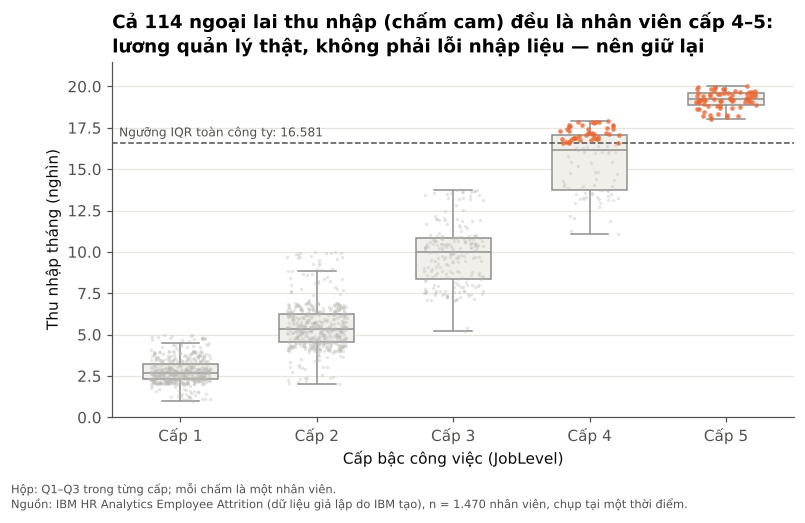

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4.2))
sns.boxplot(x=clean.JobLevel, y=clean.MonthlyIncome / 1000, color="#f1efe9", showfliers=False, width=.55, ax=ax)
sns.stripplot(x=clean.JobLevel[~iqr_flag["MonthlyIncome"]], y=clean.MonthlyIncome[~iqr_flag["MonthlyIncome"]] / 1000,
              color=NEUTRAL, alpha=.35, size=2.2, jitter=.22, ax=ax, order=[1, 2, 3, 4, 5])
sns.stripplot(x=clean.JobLevel[iqr_flag["MonthlyIncome"]], y=clean.MonthlyIncome[iqr_flag["MonthlyIncome"]] / 1000,
              color=ACCENT, alpha=.8, size=3, jitter=.22, ax=ax, order=[1, 2, 3, 4, 5])
fence_inc = out_tbl.loc["MonthlyIncome", "Ngưỡng trên IQR"]
ax.axhline(fence_inc / 1000, color=INK2, lw=1, ls="--")
ax.text(-0.45, fence_inc / 1000 + .4, f"Ngưỡng IQR toàn công ty: {fence_inc:,.0f}".replace(",", "."), fontsize=8, color=INK2)
ax.set_xticks(range(5), [f"Cấp {i}" for i in range(1, 6)]); ax.set_xlabel("Cấp bậc công việc (JobLevel)")
ax.set_ylabel("Thu nhập tháng (nghìn)"); ax.set_ylim(0, 21.5)
ax.set_title(f"Cả {int(iqr_flag['MonthlyIncome'].sum())} ngoại lai thu nhập (chấm cam) đều là nhân viên cấp 4–5:\n"
             "lương quản lý thật, không phải lỗi nhập liệu — nên giữ lại")
fig.text(0.01, -0.03, "Hộp: Q1–Q3 trong từng cấp; mỗi chấm là một nhân viên.\n" + SOURCE_NOTE, fontsize=7.5, color=INK2, va="top")
plt.show()

In [ ]:
yac = iqr_flag["YearsAtCompany"]; ysp = iqr_flag["YearsSinceLastPromotion"]; tr = iqr_flag["TrainingTimesLastYear"]
print(f"YearsAtCompany > {out_tbl.loc['YearsAtCompany', 'Ngưỡng trên IQR']:.0f} năm: {int(yac.sum())} người, tuổi trung vị {clean.Age[yac].median():.0f}, "
      f"tất cả có YearsAtCompany ≤ TotalWorkingYears = {bool((clean.YearsAtCompany <= clean.TotalWorkingYears)[yac].all())} → nhân viên gắn bó lâu.")
print(f"YearsSinceLastPromotion > {out_tbl.loc['YearsSinceLastPromotion', 'Ngưỡng trên IQR']:.1f} năm: {int(ysp.sum())} người, "
      f"{(clean.YearsAtCompany[ysp] >= 10).mean():.0%} có thâm niên từ 10 năm → lâu chưa thăng chức là hợp lý với người ở lâu.")
print(f"TrainingTimesLastYear: IQR đánh dấu {int(tr.sum())} người với giá trị {sorted(clean.TrainingTimesLastYear[tr].unique())} — "
      "chỉ vì Q1 = 2, Q3 = 3 rất sát nhau trên thang 0–6. Đây là giới hạn của hệ số 1,5 trên biến rời rạc hẹp, không phải ngoại lai thật; Z cải tiến không đánh dấu ai.")

YearsAtCompany > 18 năm: 104 người, tuổi trung vị 44, tất cả có YearsAtCompany ≤ TotalWorkingYears = True → nhân viên gắn bó lâu.
YearsSinceLastPromotion > 7.5 năm: 107 người, 95% có thâm niên từ 10 năm → lâu chưa thăng chức là hợp lý với người ở lâu.
TrainingTimesLastYear: IQR đánh dấu 238 người với giá trị [np.int64(0), np.int64(5), np.int64(6)] — chỉ vì Q1 = 2, Q3 = 3 rất sát nhau trên thang 0–6. Đây là giới hạn của hệ số 1,5 trên biến rời rạc hẹp, không phải ngoại lai thật; Z cải tiến không đánh dấu ai.


In [ ]:
KEY_OUT = ["MonthlyIncome", "TotalWorkingYears", "YearsAtCompany", "YearsSinceLastPromotion"]
any_out = iqr_flag[KEY_OUT].any(axis=1)
def key_numbers(d):
    ot = d.groupby("OverTime").Left.mean(); lv1 = d[d.JobLevel == 1].groupby("OverTime").Left.mean()
    return pd.Series({"Số dòng": len(d), "Tỷ lệ nghỉ chung (%)": 100 * d.Left.mean(),
                      "Làm thêm giờ: Có (%)": 100 * ot["Yes"], "Làm thêm giờ: Không (%)": 100 * ot["No"],
                      "Cấp 1 — Có / Không OT (điểm % chênh)": 100 * (lv1["Yes"] - lv1["No"]),
                      "Thâm niên 0–1 năm (%)": 100 * d[d.TenureBand == "0–1"].Left.mean(),
                      "Sales Representative (%)": 100 * d[d.JobRole == "Sales Representative"].Left.mean(),
                      "Thu nhập: trung bình": d.MonthlyIncome.mean(), "Thu nhập: trung vị": d.MonthlyIncome.median()})
impact = pd.DataFrame({"Toàn bộ dữ liệu": key_numbers(clean), "Bỏ dòng ngoại lai": key_numbers(clean[~any_out])}).round(1)
impact["Chênh"] = (impact.iloc[:, 1] - impact.iloc[:, 0]).round(1)
display(impact)
rate_rows = [r for r in impact.index if r.endswith("(%)")]
print(f"Bỏ {int(any_out.sum())} dòng ({any_out.mean():.1%}): các tỷ lệ nghỉ đổi tối đa {impact.loc[rate_rows, 'Chênh'].abs().max():.1f} điểm %, "
      "mọi chênh lệch giữ nguyên chiều; tỷ lệ chung tăng nhẹ vì nhóm ngoại lai (cấp cao, thâm niên dài) ít nghỉ hơn.")
print(f"Chỉ trung bình thu nhập tụt mạnh ({impact.loc['Thu nhập: trung bình', 'Chênh']:+.0f}), trung vị đổi ít hơn "
      f"({impact.loc['Thu nhập: trung vị', 'Chênh']:+.0f}) → dùng trung vị là đúng.")
lo, hi = clean.MonthlyIncome.quantile([.01, .99])
capped = clean.MonthlyIncome.clip(lo, hi)
print(f"So sánh thêm: chặn trần 1%–99% (winsorize, W4 · slide 18) chạm {int((capped != clean.MonthlyIncome).sum())} dòng, "
      f"trung bình thu nhập đổi từ {clean.MonthlyIncome.mean():.1f} còn {capped.mean():.1f}; "
      f"biến đổi log1p (W4 · slide 23) giảm skewness từ {clean.MonthlyIncome.skew():.2f} còn {np.log1p(clean.MonthlyIncome).skew():.2f}. "
      "Cả hai không cần thiết vì phân tích đã dùng trung vị và so sánh theo nhóm.")

,Toàn bộ dữ liệu,Bỏ dòng ngoại lai,Chênh
Số dòng,1470.0,1235.0,-235.0
Tỷ lệ nghỉ chung (%),16.1,17.6,1.5
Làm thêm giờ: Có (%),30.5,33.7,3.2
Làm thêm giờ: Không (%),10.4,11.2,0.8
Cấp 1 — Có / Không OT (điểm % chênh),36.8,37.1,0.3
Thâm niên 0–1 năm (%),34.9,36.6,1.7
Sales Representative (%),39.8,39.8,0.0
Thu nhập: trung bình,6502.9,5095.2,-1407.7
Thu nhập: trung vị,4919.0,4422.0,-497.0


Bỏ 235 dòng (16.0%): các tỷ lệ nghỉ đổi tối đa 3.2 điểm %, mọi chênh lệch giữ nguyên chiều; tỷ lệ chung tăng nhẹ vì nhóm ngoại lai (cấp cao, thâm niên dài) ít nghỉ hơn.
Chỉ trung bình thu nhập tụt mạnh (-1408), trung vị đổi ít hơn (-497) → dùng trung vị là đúng.
So sánh thêm: chặn trần 1%–99% (winsorize, W4 · slide 18) chạm 30 dòng, trung bình thu nhập đổi từ 6502.9 còn 6503.4; biến đổi log1p (W4 · slide 23) giảm skewness từ 1.37 còn 0.29. Cả hai không cần thiết vì phân tích đã dùng trung vị và so sánh theo nhóm.


In [ ]:
ncw9 = clean[clean.NumCompaniesWorked == 9]
ncw9_fast = int((ncw9.TotalWorkingYears < 9).sum())   # 9 công ty nhưng chưa đủ 9 năm đi làm → khó tin
decision = pd.DataFrame([
    ["MonthlyIncome", f"{int(iqr_flag['MonthlyIncome'].sum())} (IQR) · {int(out_tbl.loc['MonthlyIncome', 'Z cải tiến |M|>3,5'])} (Z cải tiến) · 0 (Z)",
     "Hiếm gặp, có thật", "Giữ", "Toàn bộ là cấp 4–5; trong cùng cấp không vượt khung lương",
     "Tóm tắt bằng trung vị; tương quan Spearman; so sánh trong từng cấp"],
    ["TotalWorkingYears, YearsAtCompany, YearsInCurrentRole, YearsWithCurrManager",
     f"{int(iqr_flag[['TotalWorkingYears', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsWithCurrManager']].any(axis=1).sum())} người (IQR, hợp các cột)",
     "Hiếm gặp, có thật", "Giữ", "Qua kiểm tra logic B8 và bước 3a; là nhân viên lớn tuổi, gắn bó lâu",
     "Gom thành nhóm thâm niên (11+ năm) nên điểm cực trị không kéo lệch kết quả"],
    ["YearsSinceLastPromotion", f"{int(ysp.sum())} (IQR)", "Hiếm gặp, có thật", "Giữ",
     "Phần lớn có thâm niên ≥ 10 năm", "Chỉ dùng trong tương quan Spearman (theo thứ hạng)"],
    ["NumCompaniesWorked", f"{int(iqr_flag['NumCompaniesWorked'].sum())} (IQR, giá trị 9) · {int(out_tbl.loc['NumCompaniesWorked', 'Z cải tiến |M|>3,5'])} (Z cải tiến, giá trị 8–9)",
     "Hiếm gặp; một phần khó tin", "Giữ",
     f"Người có 9 công ty có trung vị {ncw9.TotalWorkingYears.median():.0f} năm đi làm; {ncw9_fast} người chưa đủ 9 năm — khó tin nhưng không có nguồn để sửa",
     "Không dùng cột này để kết luận (đã gắn cờ B9 vì giá trị 0 mâu thuẫn)"],
    ["TrainingTimesLastYear", f"{int(tr.sum())} (IQR) · 0 (Z cải tiến)", "Không phải ngoại lai", "Giữ",
     "Do Q1 và Q3 quá sát trên thang rời rạc 0–6", "Không cần xử lý"],
    ["PercentSalaryHike", f"0 (IQR, Z) · {int(out_tbl.loc['PercentSalaryHike', 'Z cải tiến |M|>3,5'])} (Z cải tiến)", "Không phải ngoại lai", "Giữ",
     "Các điểm bị đánh dấu đều bằng 25%, mức trần của thang 11–25%", "Không cần xử lý"],
    ["Age, DistanceFromHome", "0 (cả ba phương pháp)", "—", "Giữ", "Không có điểm bị đánh dấu", "—"],
], columns=["Cột", "Số điểm bị đánh dấu", "Loại", "Quyết định", "Bằng chứng", "Cách giảm ảnh hưởng trong phân tích"])
decision

,Cột,Số điểm bị đánh dấu,Loại,Quyết định,Bằng chứng,Cách giảm ảnh hưởng trong phân tích
0,MonthlyIncome,114 (IQR) · 118 (Z cải tiến) · 0 (Z),"Hiếm gặp, có thật",Giữ,Toàn bộ là cấp 4–5; trong cùng cấp không vượt ...,Tóm tắt bằng trung vị; tương quan Spearman; so...
1,"TotalWorkingYears, YearsAtCompany, YearsInCurr...","149 người (IQR, hợp các cột)","Hiếm gặp, có thật",Giữ,Qua kiểm tra logic B8 và bước 3a; là nhân viên...,Gom thành nhóm thâm niên (11+ năm) nên điểm cự...
2,YearsSinceLastPromotion,107 (IQR),"Hiếm gặp, có thật",Giữ,Phần lớn có thâm niên ≥ 10 năm,Chỉ dùng trong tương quan Spearman (theo thứ h...
3,NumCompaniesWorked,"52 (IQR, giá trị 9) · 101 (Z cải tiến, giá trị...",Hiếm gặp; một phần khó tin,Giữ,Người có 9 công ty có trung vị 10 năm đi làm; ...,Không dùng cột này để kết luận (đã gắn cờ B9 v...
4,TrainingTimesLastYear,238 (IQR) · 0 (Z cải tiến),Không phải ngoại lai,Giữ,Do Q1 và Q3 quá sát trên thang rời rạc 0–6,Không cần xử lý
5,PercentSalaryHike,"0 (IQR, Z) · 18 (Z cải tiến)",Không phải ngoại lai,Giữ,"Các điểm bị đánh dấu đều bằng 25%, mức trần củ...",Không cần xử lý
6,"Age, DistanceFromHome",0 (cả ba phương pháp),—,Giữ,Không có điểm bị đánh dấu,—


## 4. Từ điển dữ liệu (mẫu Tuần 2)

In [15]:
DESC = {
    "Age": ("số nguyên", "năm", "Tuổi nhân viên"),
    "Attrition": ("phân loại", "—", "Nhân viên đã nghỉ việc (Yes/No) — biến mục tiêu"),
    "BusinessTravel": ("phân loại", "—", "Tần suất công tác: Non-Travel / Travel_Rarely / Travel_Frequently"),
    "DailyRate": ("số nguyên", "không rõ", "Không có định nghĩa trong nguồn; không khớp thu nhập (xem B10)"),
    "Department": ("phân loại", "—", "Phòng ban: R&D / Sales / Human Resources"),
    "DistanceFromHome": ("số nguyên", "không rõ (1–29)", "Khoảng cách từ nhà đến nơi làm việc"),
    "Education": ("thứ bậc", "mã 1–5", "Trình độ: 1 Dưới CĐ … 5 Tiến sĩ"),
    "EducationField": ("phân loại", "—", "Ngành học"),
    "EmployeeCount": ("số nguyên", "—", "Luôn = 1 → đã loại (B4)"),
    "EmployeeNumber": ("số nguyên", "—", "Mã nhân viên, duy nhất → chỉ mục (B5)"),
    "EnvironmentSatisfaction": ("thứ bậc", "mã 1–4", "Hài lòng với môi trường làm việc"),
    "Gender": ("phân loại", "—", "Giới tính"),
    "HourlyRate": ("số nguyên", "không rõ", "Không có định nghĩa; không khớp thu nhập (B10)"),
    "JobInvolvement": ("thứ bậc", "mã 1–4", "Mức độ gắn kết với công việc"),
    "JobLevel": ("thứ bậc", "mã 1–5", "Cấp bậc công việc (1 thấp nhất)"),
    "JobRole": ("phân loại", "—", "Chức danh (9 loại)"),
    "JobSatisfaction": ("thứ bậc", "mã 1–4", "Hài lòng với công việc"),
    "MaritalStatus": ("phân loại", "—", "Tình trạng hôn nhân: Single / Married / Divorced"),
    "MonthlyIncome": ("số nguyên", "đơn vị tiền/tháng, nguồn không ghi loại tiền", "Thu nhập hằng tháng"),
    "MonthlyRate": ("số nguyên", "không rõ", "Không có định nghĩa; không khớp thu nhập (B10)"),
    "NumCompaniesWorked": ("số nguyên", "số công ty", "Số công ty đã làm trước đây; giá trị 0 mâu thuẫn (B9)"),
    "Over18": ("phân loại", "—", "Luôn = 'Y' → đã loại (B4)"),
    "OverTime": ("phân loại", "—", "Có làm thêm giờ (Yes/No)"),
    "PercentSalaryHike": ("số nguyên", "%", "Mức tăng lương gần nhất"),
    "PerformanceRating": ("thứ bậc", "mã 1–4", "Đánh giá hiệu suất; thực tế chỉ có 3 và 4"),
    "RelationshipSatisfaction": ("thứ bậc", "mã 1–4", "Hài lòng với quan hệ đồng nghiệp"),
    "StandardHours": ("số nguyên", "giờ", "Luôn = 80 → đã loại (B4)"),
    "StockOptionLevel": ("thứ bậc", "mã 0–3", "Mức quyền chọn cổ phiếu"),
    "TotalWorkingYears": ("số nguyên", "năm", "Tổng số năm đi làm"),
    "TrainingTimesLastYear": ("số nguyên", "lần", "Số lần đào tạo năm trước"),
    "WorkLifeBalance": ("thứ bậc", "mã 1–4", "Cân bằng công việc – cuộc sống: 1 Kém … 4 Rất tốt"),
    "YearsAtCompany": ("số nguyên", "năm", "Thâm niên tại công ty"),
    "YearsInCurrentRole": ("số nguyên", "năm", "Số năm ở vị trí hiện tại"),
    "YearsSinceLastPromotion": ("số nguyên", "năm", "Số năm kể từ lần thăng chức gần nhất"),
    "YearsWithCurrManager": ("số nguyên", "năm", "Số năm làm với quản lý hiện tại"),
}
src = "IBM HR Analytics (Kaggle/OpenML), dữ liệu giả lập"
dd = pd.DataFrame([{"Cột": c, "Kiểu": t, "Đơn vị": u, "Mô tả": d,
                    "Giá trị thiếu": "Không có" if raw[c].isna().sum() == 0 else f"{raw[c].isna().sum()} NaN",
                    "Số giá trị khác nhau": raw[c].nunique(), "Nguồn": src}
                   for c, (t, u, d) in DESC.items()])
assert set(dd["Cột"]) == set(raw.columns), "Từ điển phải phủ đủ mọi cột gốc"
dd

,Cột,Kiểu,Đơn vị,Mô tả,Giá trị thiếu,Số giá trị khác nhau,Nguồn
0,Age,số nguyên,năm,Tuổi nhân viên,Không có,43,"IBM HR Analytics (Kaggle/OpenML), dữ liệu giả lập"
1,Attrition,phân loại,—,Nhân viên đã nghỉ việc (Yes/No) — biến mục tiêu,Không có,2,"IBM HR Analytics (Kaggle/OpenML), dữ liệu giả lập"
2,BusinessTravel,phân loại,—,Tần suất công tác: Non-Travel / Travel_Rarely ...,Không có,3,"IBM HR Analytics (Kaggle/OpenML), dữ liệu giả lập"
3,DailyRate,số nguyên,không rõ,Không có định nghĩa trong nguồn; không khớp th...,Không có,886,"IBM HR Analytics (Kaggle/OpenML), dữ liệu giả lập"
4,Department,phân loại,—,Phòng ban: R&D / Sales / Human Resources,Không có,3,"IBM HR Analytics (Kaggle/OpenML), dữ liệu giả lập"
5,DistanceFromHome,số nguyên,không rõ (1–29),Khoảng cách từ nhà đến nơi làm việc,Không có,29,"IBM HR Analytics (Kaggle/OpenML), dữ liệu giả lập"
6,Education,thứ bậc,mã 1–5,Trình độ: 1 Dưới CĐ … 5 Tiến sĩ,Không có,5,"IBM HR Analytics (Kaggle/OpenML), dữ liệu giả lập"
7,EducationField,phân loại,—,Ngành học,Không có,6,"IBM HR Analytics (Kaggle/OpenML), dữ liệu giả lập"
8,EmployeeCount,số nguyên,—,Luôn = 1 → đã loại (B4),Không có,1,"IBM HR Analytics (Kaggle/OpenML), dữ liệu giả lập"
9,EmployeeNumber,số nguyên,—,"Mã nhân viên, duy nhất → chỉ mục (B5)",Không có,1470,"IBM HR Analytics (Kaggle/OpenML), dữ liệu giả lập"


## 5. Thống kê mô tả — đủ bốn nhóm (Tuần 6)

**Vị trí** (trung bình, trung vị, p10/p90), **độ phân tán** (độ lệch chuẩn, IQR, CV), **hình dạng** (độ lệch – skewness, độ nhọn – kurtosis), **quan hệ** (tương quan Spearman vì nhiều biến lệch và thứ bậc).

In [16]:
NUM = ["Age", "MonthlyIncome", "TotalWorkingYears", "YearsAtCompany", "YearsInCurrentRole",
       "YearsSinceLastPromotion", "YearsWithCurrManager", "DistanceFromHome", "NumCompaniesWorked",
       "PercentSalaryHike", "TrainingTimesLastYear"]
d = clean[NUM]
stats = pd.DataFrame({
    "Trung bình": d.mean(), "Trung vị": d.median(), "p10": d.quantile(.10), "p90": d.quantile(.90),
    "Độ lệch chuẩn": d.std(), "IQR": d.quantile(.75) - d.quantile(.25), "CV": d.std() / d.mean(),
    "Skewness": d.skew(), "Kurtosis": d.kurt(),
}).round(2)
stats["Tóm tắt nên dùng"] = np.where(stats["Skewness"].abs() > 1, "Trung vị", "Trung bình")
stats

,Trung bình,Trung vị,p10,p90,Độ lệch chuẩn,IQR,CV,Skewness,Kurtosis,Tóm tắt nên dùng
Age,36.92,36.0,26.0,50.0,9.14,13.0,0.25,0.41,-0.40,Trung bình
MonthlyIncome,6502.93,4919.0,2317.6,13775.6,4707.96,5468.0,0.72,1.37,1.01,Trung vị
TotalWorkingYears,11.28,10.0,3.0,23.0,7.78,9.0,0.69,1.12,0.92,Trung vị
YearsAtCompany,7.01,5.0,1.0,15.0,6.13,6.0,0.87,1.76,3.94,Trung vị
YearsInCurrentRole,4.23,3.0,0.0,9.0,3.62,5.0,0.86,0.92,0.48,Trung bình
YearsSinceLastPromotion,2.19,1.0,0.0,7.0,3.22,3.0,1.47,1.98,3.61,Trung vị
YearsWithCurrManager,4.12,3.0,0.0,9.0,3.57,5.0,0.87,0.83,0.17,Trung bình
DistanceFromHome,9.19,7.0,1.0,23.0,8.11,12.0,0.88,0.96,-0.22,Trung bình
NumCompaniesWorked,2.69,2.0,0.0,7.0,2.50,3.0,0.93,1.03,0.01,Trung vị
PercentSalaryHike,15.21,14.0,11.0,21.0,3.66,6.0,0.24,0.82,-0.30,Trung bình


In [ ]:
CAT = ["Attrition", "OverTime", "Department", "JobRole", "MaritalStatus", "BusinessTravel", "Gender", "EducationField"]
cat_summary = pd.DataFrame([{"Biến": c, "Số nhóm": clean[c].nunique(), "Mode": clean[c].mode()[0],
                             "Tỷ lệ mode": round(clean[c].value_counts(normalize=True).iloc[0], 3)} for c in CAT])
cat_summary

,Biến,Số nhóm,Mode,Tỷ lệ mode
0,Attrition,2,No,0.839
1,OverTime,2,No,0.717
2,Department,3,Research & Development,0.654
3,JobRole,9,Sales Executive,0.222
4,MaritalStatus,3,Married,0.458
5,BusinessTravel,3,Travel_Rarely,0.710
6,Gender,2,Male,0.600
7,EducationField,6,Life Sciences,0.412


In [ ]:
REL = ["Left", "Age", "MonthlyIncome", "JobLevel", "TotalWorkingYears", "YearsAtCompany",
       "YearsInCurrentRole", "YearsWithCurrManager", "YearsSinceLastPromotion", "StockOptionLevel",
       "EnvironmentSatisfaction", "JobSatisfaction", "WorkLifeBalance", "JobInvolvement", "DistanceFromHome"]
corr = clean[REL].corr("spearman")
print("Tương quan Spearman với Left (sắp xếp):")
print(corr["Left"].drop("Left").sort_values().round(3).to_string())
print("\nCặp tương quan mạnh nhất giữa các biến giải thích:")
pairs = corr.drop("Left").drop(columns="Left").where(np.triu(np.ones((len(REL)-1,)*2), 1).astype(bool)).stack()
print(pairs.abs().sort_values(ascending=False).head(6).round(2).to_string())

Tương quan Spearman với Left (sắp xếp):
TotalWorkingYears         -0.199
MonthlyIncome             -0.198
YearsAtCompany            -0.190
JobLevel                  -0.190
YearsInCurrentRole        -0.181
YearsWithCurrManager      -0.175
StockOptionLevel          -0.172
Age                       -0.171
JobInvolvement            -0.119
JobSatisfaction           -0.103
EnvironmentSatisfaction   -0.096
YearsSinceLastPromotion   -0.053
WorkLifeBalance           -0.052
DistanceFromHome           0.079

Cặp tương quan mạnh nhất giữa các biến giải thích:
MonthlyIncome       JobLevel                0.92
YearsAtCompany      YearsInCurrentRole      0.85
                    YearsWithCurrManager    0.84
JobLevel            TotalWorkingYears       0.73
YearsInCurrentRole  YearsWithCurrManager    0.72
MonthlyIncome       TotalWorkingYears       0.71


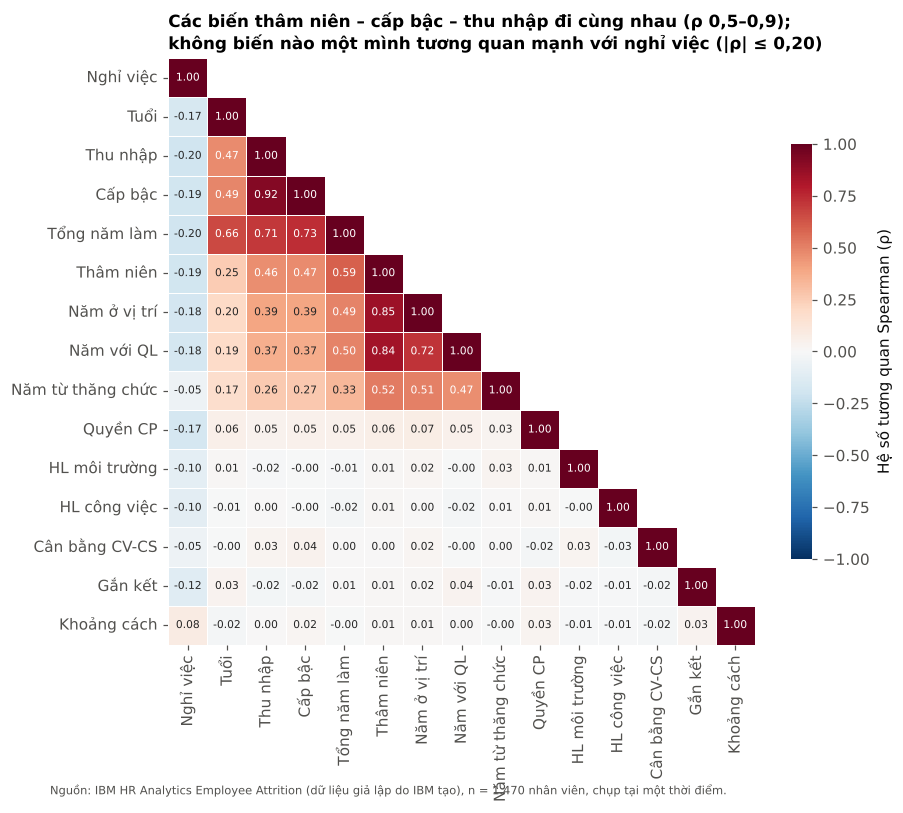

In [ ]:
VN = {"Left": "Nghỉ việc", "Age": "Tuổi", "MonthlyIncome": "Thu nhập", "JobLevel": "Cấp bậc",
      "TotalWorkingYears": "Tổng năm làm", "YearsAtCompany": "Thâm niên", "YearsInCurrentRole": "Năm ở vị trí",
      "YearsWithCurrManager": "Năm với QL", "YearsSinceLastPromotion": "Năm từ thăng chức",
      "StockOptionLevel": "Quyền CP", "EnvironmentSatisfaction": "HL môi trường", "JobSatisfaction": "HL công việc",
      "WorkLifeBalance": "Cân bằng CV-CS", "JobInvolvement": "Gắn kết", "DistanceFromHome": "Khoảng cách"}
fig, ax = plt.subplots(figsize=(8.6, 7))
mask = np.triu(np.ones_like(corr, dtype=bool), 1)
sns.heatmap(corr.rename(index=VN, columns=VN), mask=mask, cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            annot=True, fmt=".2f", annot_kws={"size": 7}, linewidths=.5, square=True,
            cbar_kws={"label": "Hệ số tương quan Spearman (ρ)", "shrink": .7}, ax=ax)
ax.grid(False)
ax.set_title("Các biến thâm niên – cấp bậc – thu nhập đi cùng nhau (ρ 0,5–0,9);\n"
             "không biến nào một mình tương quan mạnh với nghỉ việc (|ρ| ≤ 0,20)", fontsize=11)
fig.text(0, -0.08, SOURCE_NOTE, fontsize=7.5, color=INK2)
plt.show()

## 6. Phân tích theo nhóm và kiểm tra biến gây nhiễu (confounder)

Tỷ lệ nghỉ việc chung là ~16,1%. Ta xem tỷ lệ theo từng nhóm, rồi kiểm tra xem chênh lệch có **còn tồn tại trong từng nhóm con** hay không (tinh thần “faceting = groupby”, Tuần 7).

In [20]:
base = clean.Left.mean()
print(f"Tỷ lệ nghỉ việc chung: {base:.1%}  ({clean.Left.sum()} / {len(clean)})")

def rate(by):
    g = clean.groupby(by, observed=True).Left.agg(["mean", "sum", "size"])
    g.columns = ["Tỷ lệ nghỉ", "Số nghỉ", "n"]
    g["Tỷ lệ nghỉ"] = g["Tỷ lệ nghỉ"].round(3)
    return g

group_tables = {}
for c in ["OverTime", "MaritalStatus", "JobLevel", "TenureBand", "AgeBand", "IncomeQuartile", "BusinessTravel",
          "Department", "JobRole", "StockOptionLevel", "EnvironmentSatisfaction_label", "JobSatisfaction_label",
          "JobInvolvement_label", "WorkLifeBalance_label", "Gender", "PerformanceRating_label"]:
    group_tables[c] = rate(c)
    print(f"\n=== {c} ==="); print(group_tables[c].to_string())

Tỷ lệ nghỉ việc chung: 16.1%  (237 / 1470)

=== OverTime ===
          Tỷ lệ nghỉ  Số nghỉ     n
OverTime                           
No             0.104      110  1054
Yes            0.305      127   416

=== MaritalStatus ===
               Tỷ lệ nghỉ  Số nghỉ    n
MaritalStatus                          
Divorced            0.101       33  327
Married             0.125       84  673
Single              0.255      120  470

=== JobLevel ===
          Tỷ lệ nghỉ  Số nghỉ    n
JobLevel                          
1              0.263      143  543
2              0.097       52  534
3              0.147       32  218
4              0.047        5  106
5              0.072        5   69

=== TenureBand ===
            Tỷ lệ nghỉ  Số nghỉ    n
TenureBand                          
0–1              0.349       75  215
2–3              0.184       47  255
4–5              0.131       40  306
6–10             0.123       55  448
11+              0.081       20  246

=== AgeBand ===
         Tỷ l

In [ ]:
spread_rows = []
for c, t in group_tables.items():
    t = t[t.n >= 50]
    spread_rows.append({"Biến": c, "Nhóm cao nhất": t["Tỷ lệ nghỉ"].idxmax(), "Tỷ lệ cao nhất": t["Tỷ lệ nghỉ"].max(),
                        "Nhóm thấp nhất": t["Tỷ lệ nghỉ"].idxmin(), "Tỷ lệ thấp nhất": t["Tỷ lệ nghỉ"].min(),
                        "Chênh (điểm %)": round(100 * (t["Tỷ lệ nghỉ"].max() - t["Tỷ lệ nghỉ"].min()), 1)})
spread = pd.DataFrame(spread_rows).sort_values("Chênh (điểm %)", ascending=False)
spread

,Biến,Nhóm cao nhất,Tỷ lệ cao nhất,Nhóm thấp nhất,Tỷ lệ thấp nhất,Chênh (điểm %)
8,JobRole,Sales Representative,0.398,Research Director,0.025,37.3
3,TenureBand,0–1,0.349,11+,0.081,26.8
12,JobInvolvement_label,Thấp,0.337,Rất cao,0.090,24.7
2,JobLevel,1,0.263,4,0.047,21.6
0,OverTime,Yes,0.305,No,0.104,20.1
5,IncomeQuartile,Q1 (thấp),0.293,Q4 (cao),0.103,19.0
4,AgeBand,18–29,0.279,40–60,0.109,17.0
13,WorkLifeBalance_label,Kém,0.312,Khá tốt,0.142,17.0
6,BusinessTravel,Travel_Frequently,0.249,Non-Travel,0.080,16.9
9,StockOptionLevel,0,0.244,2,0.076,16.8


### 6.1 Làm thêm giờ — chênh lệch có còn khi so trong cùng cấp bậc, độ tuổi, phòng ban?

In [22]:
print("Tỷ lệ làm thêm giờ theo cấp bậc (gần như bằng nhau → cấp bậc không giải thích được hiệu ứng OT):")
print(clean.groupby("JobLevel").OverTime.apply(lambda s: (s == "Yes").mean()).round(3).to_string())
for by in ["JobLevel", "AgeBand", "Department", "IncomeQuartile"]:
    t = clean.pivot_table(index=by, columns="OverTime", values="Left", aggfunc=["mean", "size"], observed=True)
    t[("ratio", "Yes/No")] = t[("mean", "Yes")] / t[("mean", "No")]
    print(f"\n--- Làm thêm giờ × {by} ---"); print(t.round(3).to_string())

Tỷ lệ làm thêm giờ theo cấp bậc (gần như bằng nhau → cấp bậc không giải thích được hiệu ứng OT):
JobLevel
1    0.287
2    0.273
3    0.289
4    0.311
5    0.261

--- Làm thêm giờ × JobLevel ---
           mean        size       ratio
OverTime     No    Yes   No  Yes Yes/No
JobLevel                               
1         0.158  0.526  387  156  3.335
2         0.067  0.178  388  146  2.658
3         0.123  0.206  155   63  1.683
4         0.027  0.091   73   33  3.318
5         0.039  0.167   51   18  4.250

--- Làm thêm giờ × AgeBand ---
           mean        size       ratio
OverTime     No    Yes   No  Yes Yes/No
AgeBand                                
18–29     0.177  0.532  232   94  3.010
30–39     0.094  0.282  459  163  3.012
40–60     0.072  0.195  363  159  2.722

--- Làm thêm giờ × Department ---
                         mean        size       ratio
OverTime                   No    Yes   No  Yes Yes/No
Department                                           
Human Resources  

### 6.2 Thu nhập — là yếu tố riêng hay là “cái bóng” của cấp bậc?

In [23]:
print("Trung vị thu nhập theo cấp bậc và trạng thái nghỉ việc:")
inc_lvl = clean.pivot_table(index="JobLevel", columns="Attrition", values="MonthlyIncome", aggfunc="median")
inc_lvl["Chênh (Yes − No) %"] = ((inc_lvl["Yes"] / inc_lvl["No"] - 1) * 100).round(1)
print(inc_lvl.to_string())
print("\nTương quan Spearman thu nhập – cấp bậc:", round(clean[["MonthlyIncome", "JobLevel"]].corr("spearman").iloc[0, 1], 2))
print("\nCấp bậc 1 chiếm bao nhiêu % của nhóm thu nhập Q1?",
      f"{(clean[clean.IncomeQuartile == 'Q1 (thấp)'].JobLevel == 1).mean():.1%}")

Trung vị thu nhập theo cấp bậc và trạng thái nghỉ việc:
Attrition       No      Yes  Chênh (Yes − No) %
JobLevel                                       
1           2719.0   2437.0               -10.4
2           5334.5   5346.0                 0.2
3           9982.5   9887.0                -1.0
4          16307.0  13194.0               -19.1
5          19199.5  19545.0                 1.8

Tương quan Spearman thu nhập – cấp bậc: 0.92

Cấp bậc 1 chiếm bao nhiêu % của nhóm thu nhập Q1? 96.5%


### 6.3 Thâm niên và tuổi — hai yếu tố đan xen

In [24]:
print(clean.pivot_table(index="TenureBand", columns="AgeBand", values="Left", aggfunc=["mean", "size"], observed=True).round(3).to_string())

             mean                size            
AgeBand     18–29  30–39  40–60 18–29 30–39 40–60
TenureBand                                       
0–1         0.554  0.325  0.141    74    77    64
2–3         0.286  0.182  0.069    84    99    72
4–5         0.115  0.150  0.120    78   120   108
6–10        0.184  0.087  0.140    87   218   143
11+         0.333  0.083  0.074     3   108   135


### 6.4 Tình trạng hôn nhân — và một biến gây nhiễu hoàn hảo: quyền chọn cổ phiếu

In [25]:
print(clean.pivot_table(index="AgeBand", columns="MaritalStatus", values="Left", aggfunc=["mean", "size"], observed=True).round(3).to_string())
print("\nPhân bố StockOptionLevel theo tình trạng hôn nhân:")
print(pd.crosstab(clean.MaritalStatus, clean.StockOptionLevel))
print("\n→ 100% nhân viên Single có StockOptionLevel = 0: không thể tách ảnh hưởng của hôn nhân và quyền chọn cổ phiếu.")
print("\nTrong nhóm StockOptionLevel = 0, tỷ lệ nghỉ theo hôn nhân:")
print(rate(["StockOptionLevel", "MaritalStatus"]).loc[0].to_string())

                  mean                    size               
MaritalStatus Divorced Married Single Divorced Married Single
AgeBand                                                      
18–29            0.154   0.208  0.412       65     130    131
30–39            0.104   0.115  0.211      135     288    199
40–60            0.071   0.094  0.171      127     255    140

Phân bố StockOptionLevel theo tình trạng hôn nhân:
StockOptionLevel    0    1   2   3
MaritalStatus                     
Divorced            8  195  75  49
Married           153  401  83  36
Single            470    0   0   0

→ 100% nhân viên Single có StockOptionLevel = 0: không thể tách ảnh hưởng của hôn nhân và quyền chọn cổ phiếu.

Trong nhóm StockOptionLevel = 0, tỷ lệ nghỉ theo hôn nhân:
               Tỷ lệ nghỉ  Số nghỉ    n
MaritalStatus                          
Divorced            0.375        3    8
Married             0.203       31  153
Single              0.255      120  470


### 6.5 Chức danh — Sales Representative nổi bật, nhưng họ là ai?

In [ ]:
jr = rate("JobRole").sort_values("Tỷ lệ nghỉ", ascending=False)
prof = clean.groupby("JobRole").agg(Tuổi_trung_vị=("Age", "median"), Cấp_bậc_TB=("JobLevel", "mean"),
                                    Thu_nhập_trung_vị=("MonthlyIncome", "median"),
                                    Tỷ_lệ_OT=("OverTime", lambda s: (s == "Yes").mean()))
jr_prof = pd.merge(jr, prof, left_index=True, right_index=True, how="left", validate="one_to_one")
assert len(jr_prof) == len(jr)
print(jr_prof.round(2).to_string())

                           Tỷ lệ nghỉ  Số nghỉ    n  Tuổi_trung_vị  Cấp_bậc_TB  Thu_nhập_trung_vị  Tỷ_lệ_OT
JobRole                                                                                                    
Sales Representative             0.40       33   83           30.0        1.08             2579.0      0.29
Laboratory Technician            0.24       62  259           33.0        1.24             2886.0      0.24
Human Resources                  0.23       12   52           35.0        1.48             3093.0      0.25
Sales Executive                  0.18       57  326           35.0        2.33             6231.0      0.29
Research Scientist               0.16       47  292           33.0        1.20             2887.5      0.33
Healthcare Representative        0.07        9  131           39.0        2.47             6811.0      0.28
Manufacturing Director           0.07       10  145           37.0        2.45             6447.0      0.27
Manager                     

## 7. Kiểm tra độ vững: xoá ngẫu nhiên 10% số dòng thì kết luận có đổi không?

(Câu hỏi vấn đáp số 3.) Làm 5 lần, mỗi lần bỏ ngẫu nhiên 10% dòng bằng `sample(frac=0.9, random_state=i)`, rồi tính lại các chênh lệch chính.

In [27]:
res = []
for i in range(1, 6):
    s = clean.sample(frac=0.9, random_state=i)
    ot = s.groupby("OverTime").Left.mean()
    ten = s.groupby("TenureBand", observed=True).Left.mean()
    lvl1 = s[s.JobLevel == 1].groupby("OverTime").Left.mean()
    jr_s = s.groupby("JobRole").Left.mean()
    res.append({"Lần": i,
                "Chênh OT (điểm %)": 100 * (ot["Yes"] - ot["No"]),
                "Chênh OT trong cấp 1 (điểm %)": 100 * (lvl1["Yes"] - lvl1["No"]),
                "Thâm niên 0–1 năm − 11+ năm (điểm %)": 100 * (ten["0–1"] - ten["11+"]),
                "Chức danh nghỉ nhiều nhất": jr_s.idxmax()})
robust = pd.DataFrame(res).set_index("Lần").round(1)
display(robust)
for c in ["Chênh OT (điểm %)", "Chênh OT trong cấp 1 (điểm %)", "Thâm niên 0–1 năm − 11+ năm (điểm %)"]:
    print(f"{c}: dương trong {(robust[c] > 0).sum()}/5 lần, dao động {robust[c].min()} đến {robust[c].max()}")
print(f"Sales Representative nghỉ nhiều nhất trong {(robust['Chức danh nghỉ nhiều nhất'] == 'Sales Representative').sum()}/5 lần")

,Chênh OT (điểm %),Chênh OT trong cấp 1 (điểm %),Thâm niên 0–1 năm − 11+ năm (điểm %),Chức danh nghỉ nhiều nhất
Lần,,,,
1,21.3,37.6,28.8,Sales Representative
2,19.4,36.5,26.2,Sales Representative
3,19.6,35.4,25.9,Sales Representative
4,20.1,37.7,25.3,Sales Representative
5,20.0,36.2,25.8,Sales Representative


Chênh OT (điểm %): dương trong 5/5 lần, dao động 19.4 đến 21.3
Chênh OT trong cấp 1 (điểm %): dương trong 5/5 lần, dao động 35.4 đến 37.7
Thâm niên 0–1 năm − 11+ năm (điểm %): dương trong 5/5 lần, dao động 25.3 đến 28.8
Sales Representative nghỉ nhiều nhất trong 5/5 lần


## 8. Năm biểu đồ chính (headline charts)

Mỗi tiêu đề nêu **kết luận kèm con số**, một màu nhấn (cam) mang thông điệp, chú thích ghi cỡ mẫu và nguồn. Biểu đồ cột bắt đầu từ 0.

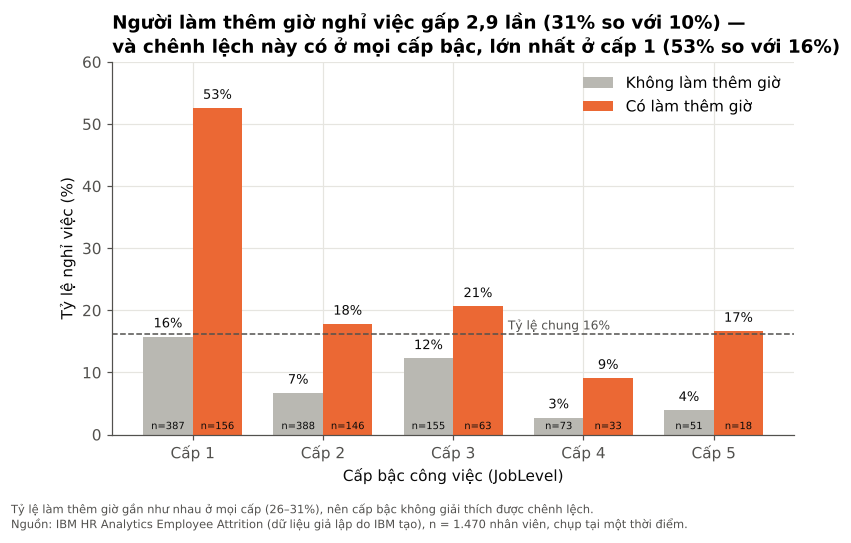

In [ ]:
def pct_axis(ax, top=None):
    ax.set_ylim(0, top)

def note(fig, extra=""):
    fig.text(0.01, -0.03, (extra + "\n" if extra else "") + SOURCE_NOTE, fontsize=7.5, color=INK2, va="top")


t = clean.pivot_table(index="JobLevel", columns="OverTime", values="Left", aggfunc="mean")
n = clean.pivot_table(index="JobLevel", columns="OverTime", values="Left", aggfunc="size")
fig, ax = plt.subplots(figsize=(8, 4.4))
x = np.arange(len(t)); w = 0.38
b1 = ax.bar(x - w/2, t["No"] * 100, w, color=NEUTRAL, label="Không làm thêm giờ")
b2 = ax.bar(x + w/2, t["Yes"] * 100, w, color=ACCENT, label="Có làm thêm giờ")
for bars, col in ((b1, "No"), (b2, "Yes")):
    for i, bar in enumerate(bars):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1, f"{bar.get_height():.0f}%",
                ha="center", va="bottom", fontsize=8.5, color=INK)
        ax.text(bar.get_x() + bar.get_width()/2, 0.5, f"n={n.iloc[i][col]}", ha="center", va="bottom", fontsize=6.5, color=INK)
ax.axhline(base * 100, color=INK2, lw=1, ls="--"); ax.text(2.42, base * 100 + .8, f"Tỷ lệ chung {base:.0%}", fontsize=8, color=INK2, ha="left")
ax.set_xticks(x, [f"Cấp {i}" for i in t.index]); pct_axis(ax, 60)
ax.set_xlabel("Cấp bậc công việc (JobLevel)"); ax.set_ylabel("Tỷ lệ nghỉ việc (%)")
ot = clean.groupby("OverTime").Left.mean()
ax.set_title(f"Người làm thêm giờ nghỉ việc gấp {ot['Yes']/ot['No']:.1f}".replace(".", ",") + f" lần ({ot['Yes']:.0%} so với {ot['No']:.0%}) —\n"
             f"và chênh lệch này có ở mọi cấp bậc, lớn nhất ở cấp 1 ({t.loc[1,'Yes']:.0%} so với {t.loc[1,'No']:.0%})")
ax.legend(frameon=False, loc="upper right")
note(fig, "Tỷ lệ làm thêm giờ gần như nhau ở mọi cấp (26–31%), nên cấp bậc không giải thích được chênh lệch.")
plt.show()

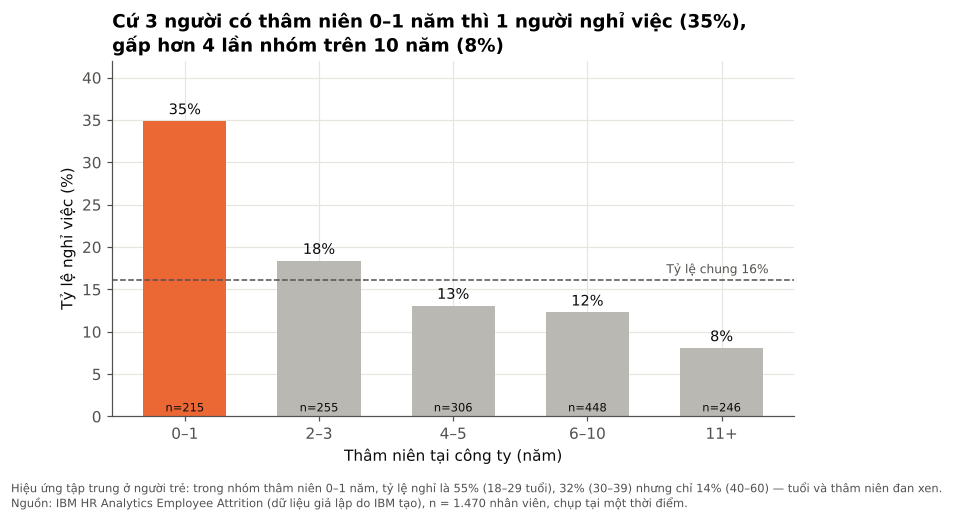

In [ ]:
tb = rate("TenureBand")
fig, ax = plt.subplots(figsize=(8, 4.2))
cols = [ACCENT if i == 0 else NEUTRAL for i in range(len(tb))]
bars = ax.bar(tb.index.astype(str), tb["Tỷ lệ nghỉ"] * 100, color=cols, width=0.62)
for bar, (r, k) in zip(bars, zip(tb["Tỷ lệ nghỉ"], tb.n)):
    ax.text(bar.get_x() + bar.get_width()/2, r * 100 + .8, f"{r:.0%}", ha="center", fontsize=9.5, color=INK)
    ax.text(bar.get_x() + bar.get_width()/2, .6, f"n={k}", ha="center", fontsize=7.5, color=INK)
ax.axhline(base * 100, color=INK2, lw=1, ls="--"); ax.text(4.35, base * 100 + .8, f"Tỷ lệ chung {base:.0%}", fontsize=8, color=INK2, ha="right")
pct_axis(ax, 42); ax.set_xlabel("Thâm niên tại công ty (năm)"); ax.set_ylabel("Tỷ lệ nghỉ việc (%)")
ax.set_title(f"Cứ 3 người có thâm niên 0–1 năm thì 1 người nghỉ việc ({tb['Tỷ lệ nghỉ'].iloc[0]:.0%}),\n"
             f"gấp hơn 4 lần nhóm trên 10 năm ({tb['Tỷ lệ nghỉ'].iloc[-1]:.0%})")
tz = clean.pivot_table(index="TenureBand", columns="AgeBand", values="Left", aggfunc="mean", observed=True)
note(fig, f"Hiệu ứng tập trung ở người trẻ: trong nhóm thâm niên 0–1 năm, tỷ lệ nghỉ là {tz.loc['0–1','18–29']:.0%} (18–29 tuổi), "
          f"{tz.loc['0–1','30–39']:.0%} (30–39) nhưng chỉ {tz.loc['0–1','40–60']:.0%} (40–60) — tuổi và thâm niên đan xen.")
plt.show()

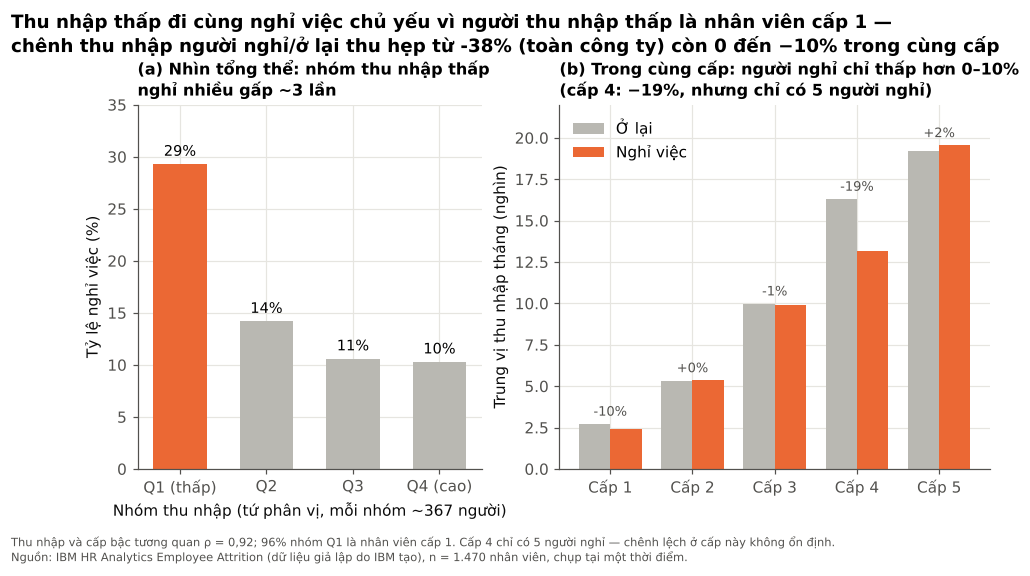

In [ ]:
iq = rate("IncomeQuartile")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 4.3), gridspec_kw={"width_ratios": [1, 1.25]})
bars = a1.bar(iq.index.astype(str), iq["Tỷ lệ nghỉ"] * 100, color=[ACCENT, NEUTRAL, NEUTRAL, NEUTRAL], width=.62)
for bar, r in zip(bars, iq["Tỷ lệ nghỉ"]):
    a1.text(bar.get_x() + bar.get_width()/2, r * 100 + .8, f"{r:.0%}", ha="center", fontsize=9.5)
pct_axis(a1, 35); a1.set_ylabel("Tỷ lệ nghỉ việc (%)"); a1.set_xlabel("Nhóm thu nhập (tứ phân vị, mỗi nhóm ~367 người)")
a1.set_title("(a) Nhìn tổng thể: nhóm thu nhập thấp\nnghỉ nhiều gấp ~3 lần", fontsize=10.5)
x2 = np.arange(len(inc_lvl)); w2 = 0.38
a2.bar(x2 - w2/2, inc_lvl["No"] / 1000, w2, color=NEUTRAL, label="Ở lại")
a2.bar(x2 + w2/2, inc_lvl["Yes"] / 1000, w2, color=ACCENT, label="Nghỉ việc")
for i, lv in enumerate(inc_lvl.index):
    top = max(inc_lvl.loc[lv, "No"], inc_lvl.loc[lv, "Yes"]) / 1000
    a2.text(i, top + .5, f"{inc_lvl.loc[lv, 'Chênh (Yes − No) %']:+.0f}%", ha="center", fontsize=8.5, color=INK2)
a2.set_xticks(x2, [f"Cấp {i}" for i in inc_lvl.index]); a2.set_ylim(0, 22)
a2.set_ylabel("Trung vị thu nhập tháng (nghìn)")
a2.set_title("(b) Trong cùng cấp: người nghỉ chỉ thấp hơn 0–10%\n(cấp 4: −19%, nhưng chỉ có 5 người nghỉ)", fontsize=10.5)
a2.legend(frameon=False, loc="upper left")
gap_all = clean.groupby("Attrition").MonthlyIncome.median(); gap_all = gap_all["Yes"] / gap_all["No"] - 1
fig.suptitle("Thu nhập thấp đi cùng nghỉ việc chủ yếu vì người thu nhập thấp là nhân viên cấp 1 —\n"
             f"chênh thu nhập người nghỉ/ở lại thu hẹp từ {gap_all:.0%} (toàn công ty) còn 0 đến −10% trong cùng cấp", x=0.01, ha="left", fontweight="bold", fontsize=12, y=1.08)
note(fig, f"Thu nhập và cấp bậc tương quan ρ = {clean[['MonthlyIncome','JobLevel']].corr('spearman').iloc[0,1]:.2f}".replace(".", ",") + "; "
          f"{(clean[clean.IncomeQuartile=='Q1 (thấp)'].JobLevel==1).mean():.0%} nhóm Q1 là nhân viên cấp 1. Cấp 4 chỉ có 5 người nghỉ — chênh lệch ở cấp này không ổn định.")
plt.show()

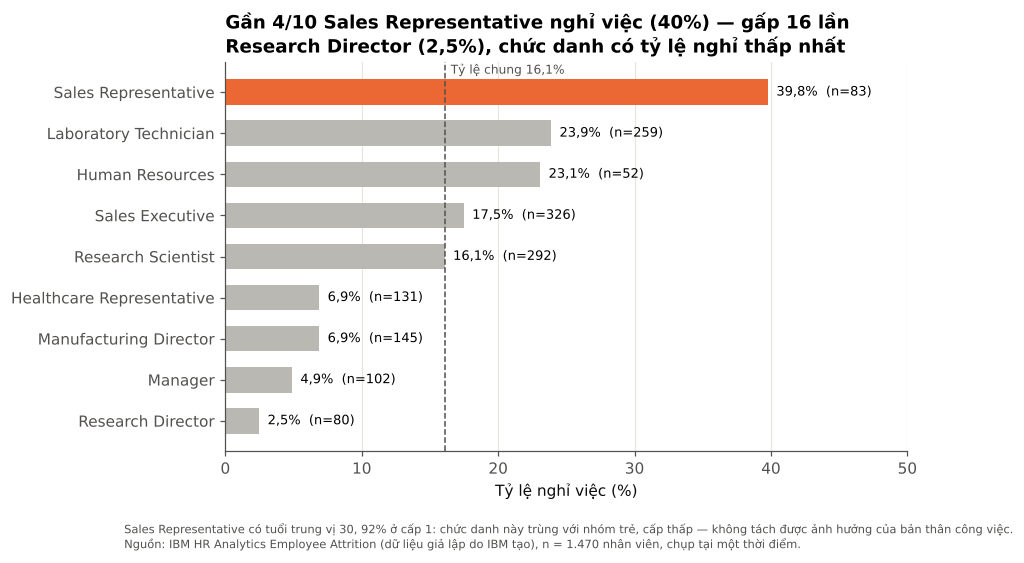

In [ ]:
jr = rate("JobRole").sort_values("Tỷ lệ nghỉ")
fig, ax = plt.subplots(figsize=(8, 4.6))
cols = [ACCENT if r == "Sales Representative" else NEUTRAL for r in jr.index]
bars = ax.barh(jr.index, jr["Tỷ lệ nghỉ"] * 100, color=cols, height=.62)
for bar, (r, k) in zip(bars, zip(jr["Tỷ lệ nghỉ"], jr.n)):
    ax.text(r * 100 + .6, bar.get_y() + bar.get_height()/2, f"{r:.1%}  (n={k})".replace(".", ","), va="center", fontsize=8.5)
ax.axvline(base * 100, color=INK2, lw=1, ls="--"); ax.text(base * 100 + .4, 8.45, f"Tỷ lệ chung {base:.1%}".replace(".", ","), fontsize=8, color=INK2)
ax.set_xlim(0, 50)
ax.set_xlabel("Tỷ lệ nghỉ việc (%)"); ax.grid(axis="y", visible=False)
sr = clean[clean.JobRole == "Sales Representative"]
ax.set_title(f"Gần 4/10 Sales Representative nghỉ việc ({jr.loc['Sales Representative','Tỷ lệ nghỉ']:.0%}) — gấp 16 lần\n"
             + f"Research Director ({jr.loc['Research Director','Tỷ lệ nghỉ']:.1%})".replace(".", ",") + ", chức danh có tỷ lệ nghỉ thấp nhất")
note(fig, f"Sales Representative có tuổi trung vị {sr.Age.median():.0f}, {(sr.JobLevel==1).mean():.0%} ở cấp 1: chức danh này trùng với nhóm trẻ, cấp thấp — "
          "không tách được ảnh hưởng của bản thân công việc.")
plt.show()

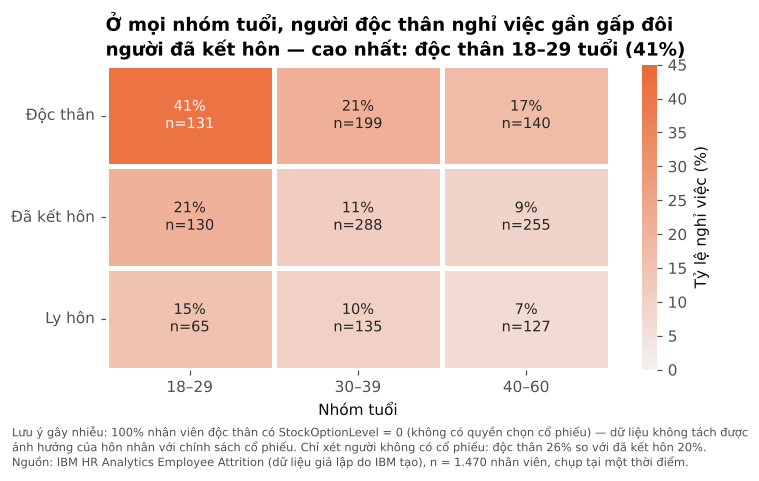

In [ ]:
hm = clean.pivot_table(index="MaritalStatus", columns="AgeBand", values="Left", aggfunc="mean", observed=True).loc[["Single", "Married", "Divorced"]]
hn = clean.pivot_table(index="MaritalStatus", columns="AgeBand", values="Left", aggfunc="size", observed=True).loc[hm.index]
annot = df_map(hm, lambda v: f"{v:.0%}") + "\n" + df_map(hn, lambda v: f"n={v}")
fig, ax = plt.subplots(figsize=(7.4, 3.6))
sns.heatmap(hm * 100, annot=annot, fmt="", cmap=sns.light_palette(ACCENT, as_cmap=True), vmin=0, vmax=45,
            linewidths=2, linecolor="white", cbar_kws={"label": "Tỷ lệ nghỉ việc (%)"},
            annot_kws={"fontsize": 9.5}, ax=ax)
ax.grid(False); ax.set_xlabel("Nhóm tuổi"); ax.set_ylabel("")
ax.set_yticklabels(["Độc thân", "Đã kết hôn", "Ly hôn"], rotation=0)
ax.set_title("Ở mọi nhóm tuổi, người độc thân nghỉ việc gần gấp đôi\nngười đã kết hôn — cao nhất: độc thân 18–29 tuổi (41%)")
note(fig, "Lưu ý gây nhiễu: 100% nhân viên độc thân có StockOptionLevel = 0 (không có quyền chọn cổ phiếu) — "
          "dữ liệu không tách được\nảnh hưởng của hôn nhân với chính sách cổ phiếu. Chỉ xét người không có cổ phiếu: độc thân 26% so với đã kết hôn 20%.")
plt.show()

## 9. Tóm tắt phát hiện (chi tiết trong báo cáo PDF)

1. **Làm thêm giờ** gắn với tỷ lệ nghỉ cao gấp ~3 lần; chênh lệch còn nguyên trong mọi cấp bậc, nhóm tuổi, phòng ban, nhóm thu nhập (Biểu đồ 1).
2. **Thâm niên 0–1 năm** là giai đoạn rủi ro: ~35% nghỉ việc; hiệu ứng mạnh ở người dưới 40 tuổi, yếu ở nhóm 40–60 (Biểu đồ 2).
3. **Thu nhập thấp** gắn với nghỉ việc ở mức tổng thể, nhưng phần lớn là do cấp bậc; trong cùng cấp, chênh thu nhập chỉ còn 0 đến −10% (Biểu đồ 3).
4. **Sales Representative** có tỷ lệ nghỉ 40% — nhưng trùng với nhóm trẻ, cấp 1 (Biểu đồ 4).
5. **Độc thân** nghỉ nhiều hơn ở mọi nhóm tuổi, nhưng trùng hoàn toàn với việc không có quyền chọn cổ phiếu (Biểu đồ 5).

Tất cả là **quan hệ đi kèm (association)**, không phải nhân quả. Kiểm định thống kê (Tuần 9) là bước tiếp theo.

In [33]:
key = {
    "Tỷ lệ nghỉ việc chung": f"{base:.1%}",
    "Làm thêm giờ: Có / Không": f"{ot['Yes']:.1%} / {ot['No']:.1%}",
    "Thâm niên 0–1 năm / 11+ năm": f"{tb['Tỷ lệ nghỉ'].iloc[0]:.1%} / {tb['Tỷ lệ nghỉ'].iloc[-1]:.1%}",
    "Thu nhập Q1 / Q4": f"{iq['Tỷ lệ nghỉ'].iloc[0]:.1%} / {iq['Tỷ lệ nghỉ'].iloc[-1]:.1%}",
    "Sales Representative": f"{jr.loc['Sales Representative', 'Tỷ lệ nghỉ']:.1%}",
    "Độc thân / Đã kết hôn": f"{clean[clean.MaritalStatus == 'Single'].Left.mean():.1%} / {clean[clean.MaritalStatus == 'Married'].Left.mean():.1%}",
}
pd.Series(key, name="Giá trị").to_frame()

,Giá trị
Tỷ lệ nghỉ việc chung,16.1%
Làm thêm giờ: Có / Không,30.5% / 10.4%
Thâm niên 0–1 năm / 11+ năm,34.9% / 8.1%
Thu nhập Q1 / Q4,29.3% / 10.3%
Sales Representative,39.8%
Độc thân / Đã kết hôn,25.5% / 12.5%
